In [46]:
import pandas as pd
import numpy as np

In [47]:
raw_df = pd.read_csv('../data/application_train.csv')

In [48]:
pd.set_option('display.max_rows', 20)
raw_df
y = raw_df['TARGET']
X = raw_df.drop(columns=['TARGET', 'SK_ID_CURR'])

In [ ]:
from sklearn.model_selection import train_test_split

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, random_state=42, test_size=0.2)

In [32]:
X_train['DAYS_EMPLOYED'].describe()

count    246008.000000
mean      63581.163637
std      141081.696923
min      -17912.000000
25%       -2762.000000
50%       -1215.000000
75%        -291.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [33]:
results_na = (X_train.isna().mean() > 0.5)
bad_cols = X_train.columns[results_na].tolist()

In [34]:
feature_columns = X_train.columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'str']).columns.tolist()

In [35]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [36]:
from src.preprocessing import prepare_features
from src.model import make_catboost

In [37]:
model = make_catboost()


In [38]:
X_train = prepare_features(X_train,feature_columns, categorical_cols)
X_val = prepare_features(X_val, feature_columns, categorical_cols)

In [39]:
print('Income_div_credit' in X_train.columns)
print(X_train['Income_div_credit'].head())

True
181648    0.395570
229245    0.556483
122525    0.185224
306311    0.284700
300658    0.706714
Name: Income_div_credit, dtype: float64


In [ ]:
# model.fit(X_train, y_train, cat_features=categorical_cols)
# model.save_model('../artifacts/catboost.cbm')

0:	learn: 0.6873156	total: 144ms	remaining: 43.2s
50:	learn: 0.6102124	total: 6.85s	remaining: 33.5s
100:	learn: 0.5991465	total: 13.2s	remaining: 26s
150:	learn: 0.5940240	total: 19.2s	remaining: 19s
200:	learn: 0.5900723	total: 25.6s	remaining: 12.6s
250:	learn: 0.5871812	total: 31.8s	remaining: 6.2s
299:	learn: 0.5840158	total: 38s	remaining: 0us


In [ ]:
pd.set_option('display.max_rows', None )
numeric_cols = X_train.select_dtypes(include='number').columns

numeric_importance = importance[
    importance['feature'].isin(numeric_cols)
].sort_values('importance', ascending=False)

print(numeric_importance.to_string(index=False))

                     feature  importance
                EXT_SOURCE_3   31.420528
                EXT_SOURCE_2   20.912232
                EXT_SOURCE_1    8.272738
            Price_div_amount    4.202355
               DAYS_EMPLOYED    4.016197
                  DAYS_BIRTH    3.337925
             AMT_GOODS_PRICE    2.956577
                 AMT_ANNUITY    2.334098
                  AMT_CREDIT    1.720880
                 OWN_CAR_AGE    1.131917
             DAYS_ID_PUBLISH    0.931455
 REGION_RATING_CLIENT_W_CITY    0.792077
             FLAG_DOCUMENT_3    0.744803
    DEF_60_CNT_SOCIAL_CIRCLE    0.523565
      DAYS_LAST_PHONE_CHANGE    0.509364
          Annuity_div_income    0.496780
            FLAG_DOCUMENT_16    0.399842
   AMT_REQ_CREDIT_BUREAU_QRT    0.356005
    DEF_30_CNT_SOCIAL_CIRCLE    0.355949
  AMT_REQ_CREDIT_BUREAU_YEAR    0.308764
             FLAG_WORK_PHONE    0.287213
           Income_div_credit    0.278666
           DAYS_REGISTRATION    0.238752
            FLAG

In [ ]:
pd.set_option('display.max_rows', None )
numeric_cols = X_train.select_dtypes(include='number').columns

numeric_importance = importance[
    importance['feature'].isin(numeric_cols)
].sort_values('importance', ascending=False)

print(numeric_importance.to_string(index=False))

                     feature  importance
                EXT_SOURCE_3   31.420528
                EXT_SOURCE_2   20.912232
                EXT_SOURCE_1    8.272738
            Price_div_amount    4.202355
               DAYS_EMPLOYED    4.016197
                  DAYS_BIRTH    3.337925
             AMT_GOODS_PRICE    2.956577
                 AMT_ANNUITY    2.334098
                  AMT_CREDIT    1.720880
                 OWN_CAR_AGE    1.131917
             DAYS_ID_PUBLISH    0.931455
 REGION_RATING_CLIENT_W_CITY    0.792077
             FLAG_DOCUMENT_3    0.744803
    DEF_60_CNT_SOCIAL_CIRCLE    0.523565
      DAYS_LAST_PHONE_CHANGE    0.509364
          Annuity_div_income    0.496780
            FLAG_DOCUMENT_16    0.399842
   AMT_REQ_CREDIT_BUREAU_QRT    0.356005
    DEF_30_CNT_SOCIAL_CIRCLE    0.355949
  AMT_REQ_CREDIT_BUREAU_YEAR    0.308764
             FLAG_WORK_PHONE    0.287213
           Income_div_credit    0.278666
           DAYS_REGISTRATION    0.238752
            FLAG

In [ ]:
# pd.set_option('display.max_rows', None )
# numeric_cols = X_train.select_dtypes(include='number').columns

# numeric_importance = importance[
#     importance['feature'].isin(numeric_cols)
# ].sort_values('importance', ascending=False)

# print(numeric_importance.to_string(index=False))

                     feature  importance
                EXT_SOURCE_3   31.420528
                EXT_SOURCE_2   20.912232
                EXT_SOURCE_1    8.272738
            Price_div_amount    4.202355
               DAYS_EMPLOYED    4.016197
                  DAYS_BIRTH    3.337925
             AMT_GOODS_PRICE    2.956577
                 AMT_ANNUITY    2.334098
                  AMT_CREDIT    1.720880
                 OWN_CAR_AGE    1.131917
             DAYS_ID_PUBLISH    0.931455
 REGION_RATING_CLIENT_W_CITY    0.792077
             FLAG_DOCUMENT_3    0.744803
    DEF_60_CNT_SOCIAL_CIRCLE    0.523565
      DAYS_LAST_PHONE_CHANGE    0.509364
          Annuity_div_income    0.496780
            FLAG_DOCUMENT_16    0.399842
   AMT_REQ_CREDIT_BUREAU_QRT    0.356005
    DEF_30_CNT_SOCIAL_CIRCLE    0.355949
  AMT_REQ_CREDIT_BUREAU_YEAR    0.308764
             FLAG_WORK_PHONE    0.287213
           Income_div_credit    0.278666
           DAYS_REGISTRATION    0.238752
            FLAG

In [ ]:
model.load_model('../artifacts/catboost.cbm')

In [42]:
from sklearn.metrics import roc_auc_score

In [43]:
train_proba = model.predict_proba(X_train)[:, 1]
val_proba = model.predict_proba(X_val)[:, 1]

print(
    f'Train roc-auc-score: {roc_auc_score(y_train, train_proba)}\n'
    f'Val roc-auc-score: {roc_auc_score(y_val, val_proba)}'
    )

Train roc-auc-score: 0.7603345798412258
Val roc-auc-score: 0.7581797724686196


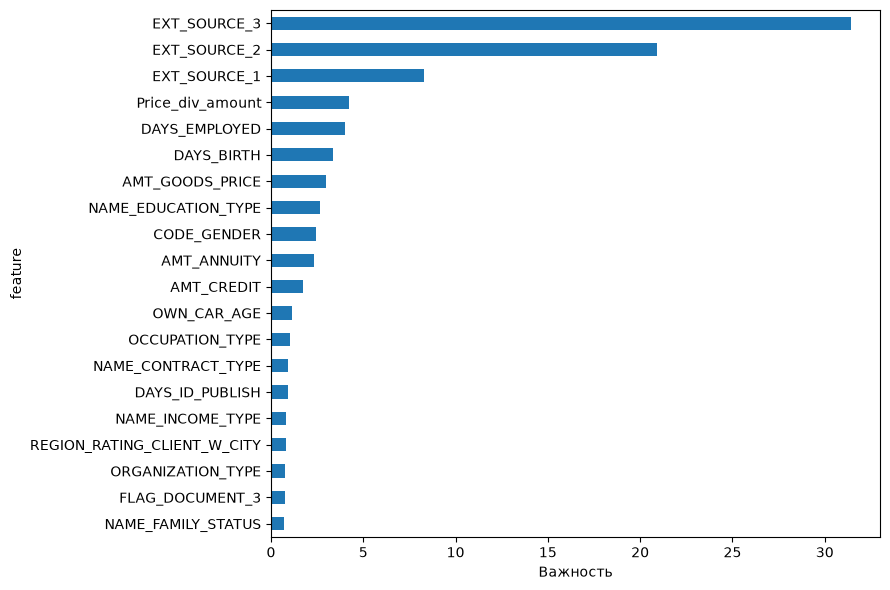

In [44]:
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    'feature': model.feature_names_,
    'importance': model.get_feature_importance()
}).sort_values('importance', ascending=False)



importance.head(20).sort_values('importance').plot.barh(
    x='feature',
    y='importance',
    legend=False,
    figsize=(9, 6)
)

plt.xlabel('Важность')
plt.tight_layout()
plt.show()

In [ ]:
pd.set_option('display.max_rows', None )
numeric_cols = X_train.select_dtypes(include='number').columns

numeric_importance = importance[
    importance['feature'].isin(numeric_cols)
].sort_values('importance', ascending=False)

print(numeric_importance.to_string(index=False))

                     feature  importance
                EXT_SOURCE_3   31.420528
                EXT_SOURCE_2   20.912232
                EXT_SOURCE_1    8.272738
            Price_div_amount    4.202355
               DAYS_EMPLOYED    4.016197
                  DAYS_BIRTH    3.337925
             AMT_GOODS_PRICE    2.956577
                 AMT_ANNUITY    2.334098
                  AMT_CREDIT    1.720880
                 OWN_CAR_AGE    1.131917
             DAYS_ID_PUBLISH    0.931455
 REGION_RATING_CLIENT_W_CITY    0.792077
             FLAG_DOCUMENT_3    0.744803
    DEF_60_CNT_SOCIAL_CIRCLE    0.523565
      DAYS_LAST_PHONE_CHANGE    0.509364
          Annuity_div_income    0.496780
            FLAG_DOCUMENT_16    0.399842
   AMT_REQ_CREDIT_BUREAU_QRT    0.356005
    DEF_30_CNT_SOCIAL_CIRCLE    0.355949
  AMT_REQ_CREDIT_BUREAU_YEAR    0.308764
             FLAG_WORK_PHONE    0.287213
           Income_div_credit    0.278666
           DAYS_REGISTRATION    0.238752
            FLAG

In [51]:
34



34